### Import bibliotek

`moje_kolory` dla lepszej wizualizacji wyników

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from matplotlib.colors import ListedColormap
import numpy.linalg
from lab3.wzorce_cyfr import (cyfra_0, cyfra_1, cyfra_2, cyfra_3, cyfra_4,
                              cyfra_5, cyfra_6, cyfra_7, cyfra_8, cyfra_9)

moje_kolory = ListedColormap(['darkblue', 'yellow'])

### Przygotowanie danych

In [2]:
wzorce = [cyfra_0, cyfra_1, cyfra_2, cyfra_3, cyfra_4,
          cyfra_5, cyfra_6, cyfra_7, cyfra_8, cyfra_9]

### Metoda na dodanie szumu

In [3]:
def dodajSzum(obraz, poziom_szumu):
    zaszumiony_obraz = obraz.copy().flatten()
    liczba_pikseli = len(zaszumiony_obraz)

    ile_zmienic = int(liczba_pikseli * (poziom_szumu / 100.0))
    indeksy_do_zepsucia = random.sample(range(liczba_pikseli), ile_zmienic)

    for i in indeksy_do_zepsucia:
        zaszumiony_obraz[i] *= -1

    return zaszumiony_obraz.reshape((8, 8))

### Wzorce zaszumione

In [4]:
wzorce_zaszumione_10 = []
wzorce_zaszumione_20 = []
wzorce_zaszumione_30 = []

for wzorzec in wzorce:
    wzorzec_zaszumiony = dodajSzum(wzorzec, 10)
    wzorce_zaszumione_10.append(wzorzec_zaszumiony)

for wzorzec in wzorce:
    wzorzec_zaszumiony = dodajSzum(wzorzec, 20)
    wzorce_zaszumione_20.append(wzorzec_zaszumiony)

for wzorzec in wzorce:
    wzorzec_zaszumiony = dodajSzum(wzorzec, 30)
    wzorce_zaszumione_30.append(wzorzec_zaszumiony)

### Metoda do wyświetlania wzorców przed i po zaszumieniu

In [5]:
def wyswietlPrzedIPoZaszumieniu(wzorzec, poziomZaszumienia):
    fig, osie = plt.subplots(1, 2)
    osie[0].imshow(wzorzec, cmap=moje_kolory)
    osie[0].set_title("Oryginał")
    osie[1].imshow(dodajSzum(wzorzec, poziomZaszumienia), cmap=moje_kolory)
    osie[1].set_title(f"{poziomZaszumienia}% zaszumienia")
    for os in osie:
        os.axis('off')
    plt.show()

### Obliczanie pola lokalnego neuronu i jego aktualizacja

Zastosowanie tolerancji 1e-7 ze względu na zaokrąglenia ułamków z pseudoinwersji

In [6]:
def oblicz_pole_lokalne(i, wagi, stan_sieci):
    h_i = np.dot(wagi[i], stan_sieci)
    return h_i

def aktualizuj_neuron(i, wagi, stan_sieci):
    h_i = oblicz_pole_lokalne(i, wagi, stan_sieci)
    if h_i > 1e-7:
        stan_sieci[i] = 1
    elif h_i < -1e-7:
        stan_sieci[i] = -1
    return stan_sieci

### Metoda do odtwarzania obrazów

In [7]:
def odtworz_obraz(zaszumiony_obraz, wagi, maks_iteracji):
    stan_sieci = zaszumiony_obraz.copy().flatten()
    liczba_neuronow = len(stan_sieci)
    for i in range(maks_iteracji):
        liczba_zmian = 0
        for i in range(liczba_neuronow):
            stary_stan = stan_sieci[i]
            stan_sieci = aktualizuj_neuron(i, wagi, stan_sieci)
            if stary_stan != stan_sieci[i]:
                liczba_zmian += 1
        if liczba_zmian == 0:
            break
    return stan_sieci.reshape((8, 8))

### Metoda Hebba

In [8]:
liczba_neuronow = 64
wagi = np.zeros((liczba_neuronow, liczba_neuronow))

for wzorzec in wzorce[:3]:
    wzorzec_na_plasko = wzorzec.flatten()
    for i in range(liczba_neuronow):
        for j in range(liczba_neuronow):
            if i != j:
                wagi[i, j] += wzorzec_na_plasko[i] * wzorzec_na_plasko[j]

wagi_hebba = wagi / liczba_neuronow

### Sprawdzenie wymagane w materiałach do zajęć

In [9]:
print("\n===Testy macierzy wag===\n")
print("\nCzy macierz wag jest symetryczna?")
czy_symetryczna = np.allclose(wagi, wagi.T)
print(czy_symetryczna)
print("\nCzy na przekatnej są zera?")
przekatna = np.diag(wagi)
czy_zera_na_przekatnej = np.all(przekatna == 0)
print(czy_zera_na_przekatnej)


===Testy macierzy wag===


Czy macierz wag jest symetryczna?
True

Czy na przekatnej są zera?
True


### Wizualizacja działania sieci Hopfielda

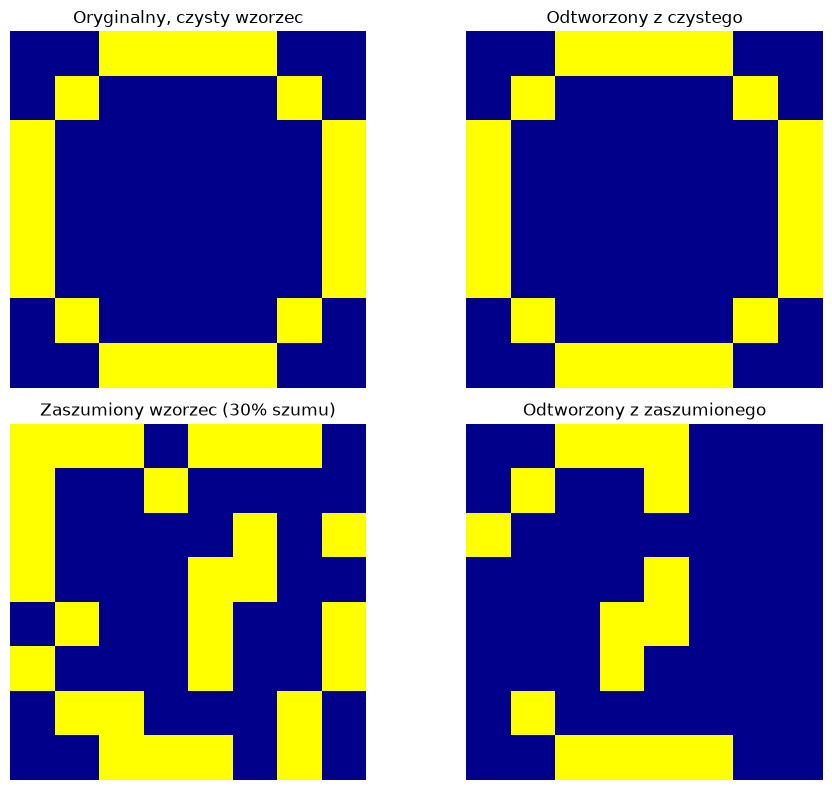

In [10]:
wzorzec_testowy = wzorce[0]
zaszumiony_testowy = wzorce_zaszumione_30[0]
odtworzony = odtworz_obraz(wzorzec_testowy, wagi, 10)
odtworzony_zaszumiony = odtworz_obraz(zaszumiony_testowy, wagi, 10)
fig, osie = plt.subplots(2, 2, figsize=(10, 8))

osie[0, 0].imshow(wzorzec_testowy, cmap=moje_kolory)
osie[0, 0].set_title("Oryginalny, czysty wzorzec")
osie[0, 0].axis('off')

osie[0, 1].imshow(odtworzony, cmap=moje_kolory)
osie[0, 1].set_title("Odtworzony z czystego")
osie[0, 1].axis('off')

osie[1, 0].imshow(zaszumiony_testowy, cmap=moje_kolory)
osie[1, 0].set_title("Zaszumiony wzorzec (30% szumu)")
osie[1, 0].axis('off')

osie[1, 1].imshow(odtworzony_zaszumiony, cmap=moje_kolory)
osie[1, 1].set_title("Odtworzony z zaszumionego")
osie[1, 1].axis('off')

plt.tight_layout()
plt.show()

# Pseudoinwersja i Storkey
### Przygotowanie danych

In [11]:
X = np.array([
    cyfra_0.flatten(),
    cyfra_1.flatten(),
    cyfra_2.flatten(),
    cyfra_3.flatten(),
    cyfra_4.flatten(),
    cyfra_5.flatten(),
    cyfra_6.flatten(),
    cyfra_7.flatten(),
    cyfra_8.flatten(),
    cyfra_9.flatten()
])

### Pseudoinwersja

In [12]:
wagi_pseudoinwersja = X.T @ numpy.linalg.pinv(X @ X.T) @ X

np.fill_diagonal(wagi_pseudoinwersja, 0)

print("Czy macierz pseudoinwersji jest symetryczna?", np.allclose(wagi_pseudoinwersja, wagi_pseudoinwersja.T))

Czy macierz pseudoinwersji jest symetryczna? True


### Metoda na regułę Storkeya

In [13]:
def storkey(X, liczba_neuronow = 64):
    w = np.zeros((liczba_neuronow, liczba_neuronow))
    for wzorzec in X:
        w_nowe = w.copy()
        h = w @ wzorzec
        for i in range(liczba_neuronow):
            for j in range(liczba_neuronow):
                if i != j:
                    h_ij = h[i] - w[i, j] * wzorzec[j]
                    h_ji = h[j] - w[j, i] * wzorzec[i]
                    w_nowe[i, j] += (wzorzec[i] * wzorzec[j] - wzorzec[i] * h_ji - wzorzec[j] * h_ij) / liczba_neuronow
        w = w_nowe
        np.fill_diagonal(w, 0)
    return w

wagi_storkey = storkey(X)

### Odtworzenie zaszumionych obrazów cyfry 3

In [14]:
zaszumiona_3 = wzorce_zaszumione_30[3]

odtworzona_3_pseudoinwersja = odtworz_obraz(zaszumiona_3, wagi_pseudoinwersja, 10)
odtworzona_3_hebb = odtworz_obraz(zaszumiona_3, wagi_hebba, 10)
odtworzona_3_storkey = odtworz_obraz(zaszumiona_3, wagi_storkey, 10)


### Porównanie metod Hebba, pseudoinwersji i Storkey'a

Czy macierz jest symetryczna?
True
===PORÓWNANIE METOD===


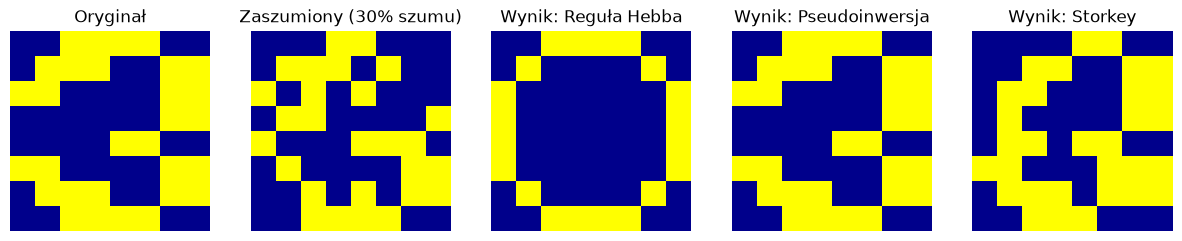

In [15]:
print("Czy macierz jest symetryczna?")
print(np.allclose(wagi_pseudoinwersja, wagi_pseudoinwersja.T))

print("===PORÓWNANIE METOD===")
f, o = plt.subplots(1, 5, figsize=(15, 3))
o[0].imshow(cyfra_3, cmap=moje_kolory)
o[0].set_title("Oryginał")

o[1].imshow(zaszumiona_3, cmap=moje_kolory)
o[1].set_title("Zaszumiony (30% szumu)")

o[2].imshow(odtworzona_3_hebb, cmap=moje_kolory)
o[2].set_title("Wynik: Reguła Hebba")

o[3].imshow(odtworzona_3_pseudoinwersja, cmap=moje_kolory)
o[3].set_title("Wynik: Pseudoinwersja")

o[4].imshow(odtworzona_3_storkey, cmap=moje_kolory)
o[4].set_title("Wynik: Storkey")

for os in o:
    os.axis('off')
plt.show()